# Entrega 1 — Perceptrón Multicapa para clasificación de texto

**Curso:** Redes Neuronales · Universidad del Valle · 2026-2

**Integrantes:** Nicolás Garcés (218066) · Juan Pablo Ante (2140132)

Este notebook presenta el desarrollo de la primera entrega: clasificación de
documentos del corpus **20 Newsgroups** en 20 categorías mediante una red
**Perceptrón Multicapa (MLP)** implementada en **Keras/TensorFlow**.

El flujo completo (descarga, preprocesamiento, entrenamiento, ajuste de
hiperparámetros y evaluación) está implementado en los módulos de `src/` y se
reproduce con `python -m src.experiments`. Aquí se cargan los artefactos ya
entrenados, se analizan los resultados y se ejecuta una demostración.

In [1]:
# Si el notebook se ejecuta desde notebooks/, agrega la raíz del proyecto al path
from pathlib import Path
import os
import sys

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.config import PRIMARY_CONFIG, RESULTS_DIR, SEED
from src.data import load_dataframe, dataframe_summary
from src.predict import load_trained_model, predict_texts

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
print("Raíz del proyecto:", ROOT)
print("Semilla:", SEED)

Raíz del proyecto: /mnt/Bicho/Universidad/Redes neuronales/Proyecto
Semilla: 42


## 1. Conjunto de datos

**20 Newsgroups** (Lang, 1995) es una colección de aproximadamente 20.000
mensajes publicados en 20 grupos de noticias de Usenet durante 1993. Es un
problema de clasificación multiclase (no multietiqueta) balanceado de forma
aproximada, ampliamente usado como referencia en clasificación de texto.

Se emplea la partición oficial de scikit-learn: 11.314 documentos de
entrenamiento y 7.532 de prueba. Para evitar fuga de información se eliminan
**cabeceras, pies de página y citas**, que contienen el nombre del grupo y
delatarían la etiqueta.

In [2]:
train, test, label_names = load_dataframe()
summary = dataframe_summary(train, test)

stats = pd.DataFrame(
    {
        "Valor": [
            summary["n_train"], summary["n_test"], summary["n_classes"],
            summary["words_mean"], summary["words_median"],
            summary["words_p95"], summary["words_max"], summary["empty_docs"],
        ]
    },
    index=[
        "Documentos de entrenamiento", "Documentos de prueba", "Clases",
        "Palabras por documento (media)", "Palabras por documento (mediana)",
        "Percentil 95 de longitud", "Longitud máxima", "Documentos vacíos",
    ],
)
stats["Valor"] = stats["Valor"].apply(lambda v: f"{v:,.1f}" if isinstance(v, float) else f"{v:,}")
display(stats)

display(train[["label_name", "text"]].head(4))

,Valor
Documentos de entrenamiento,"11,314.0"
Documentos de prueba,"7,532.0"
Clases,20.0
Palabras por documento (media),185.8
Palabras por documento (mediana),83.0
Percentil 95 de longitud,572.4
Longitud máxima,"11,765.0"
Documentos vacíos,300.0


,label_name,text
0,rec.autos,"I was wondering if anyone out there could enlighten me on this car I saw\nthe other day. It was a 2-door sports car,..."
1,comp.sys.mac.hardware,A fair number of brave souls who upgraded their SI clock oscillator have\nshared their experiences for this poll. Pl...
2,comp.sys.mac.hardware,"well folks, my mac plus finally gave up the ghost this weekend after\nstarting life as a 512k way back in 1985. soo..."
3,comp.graphics,\nDo you have Weitek's address/phone number? I'd like to get some information\nabout this chip.\n


label_name,rec.sport.hockey,soc.religion.christian,rec.motorcycles,rec.sport.baseball,sci.crypt,rec.autos,sci.med,sci.space,comp.windows.x,comp.os.ms-windows.misc,sci.electronics,comp.sys.ibm.pc.hardware,misc.forsale,comp.graphics,comp.sys.mac.hardware,talk.politics.mideast,talk.politics.guns,alt.atheism,talk.politics.misc,talk.religion.misc
Documentos,600,599,598,597,595,594,594,593,593,591,591,590,585,584,578,564,546,480,465,377


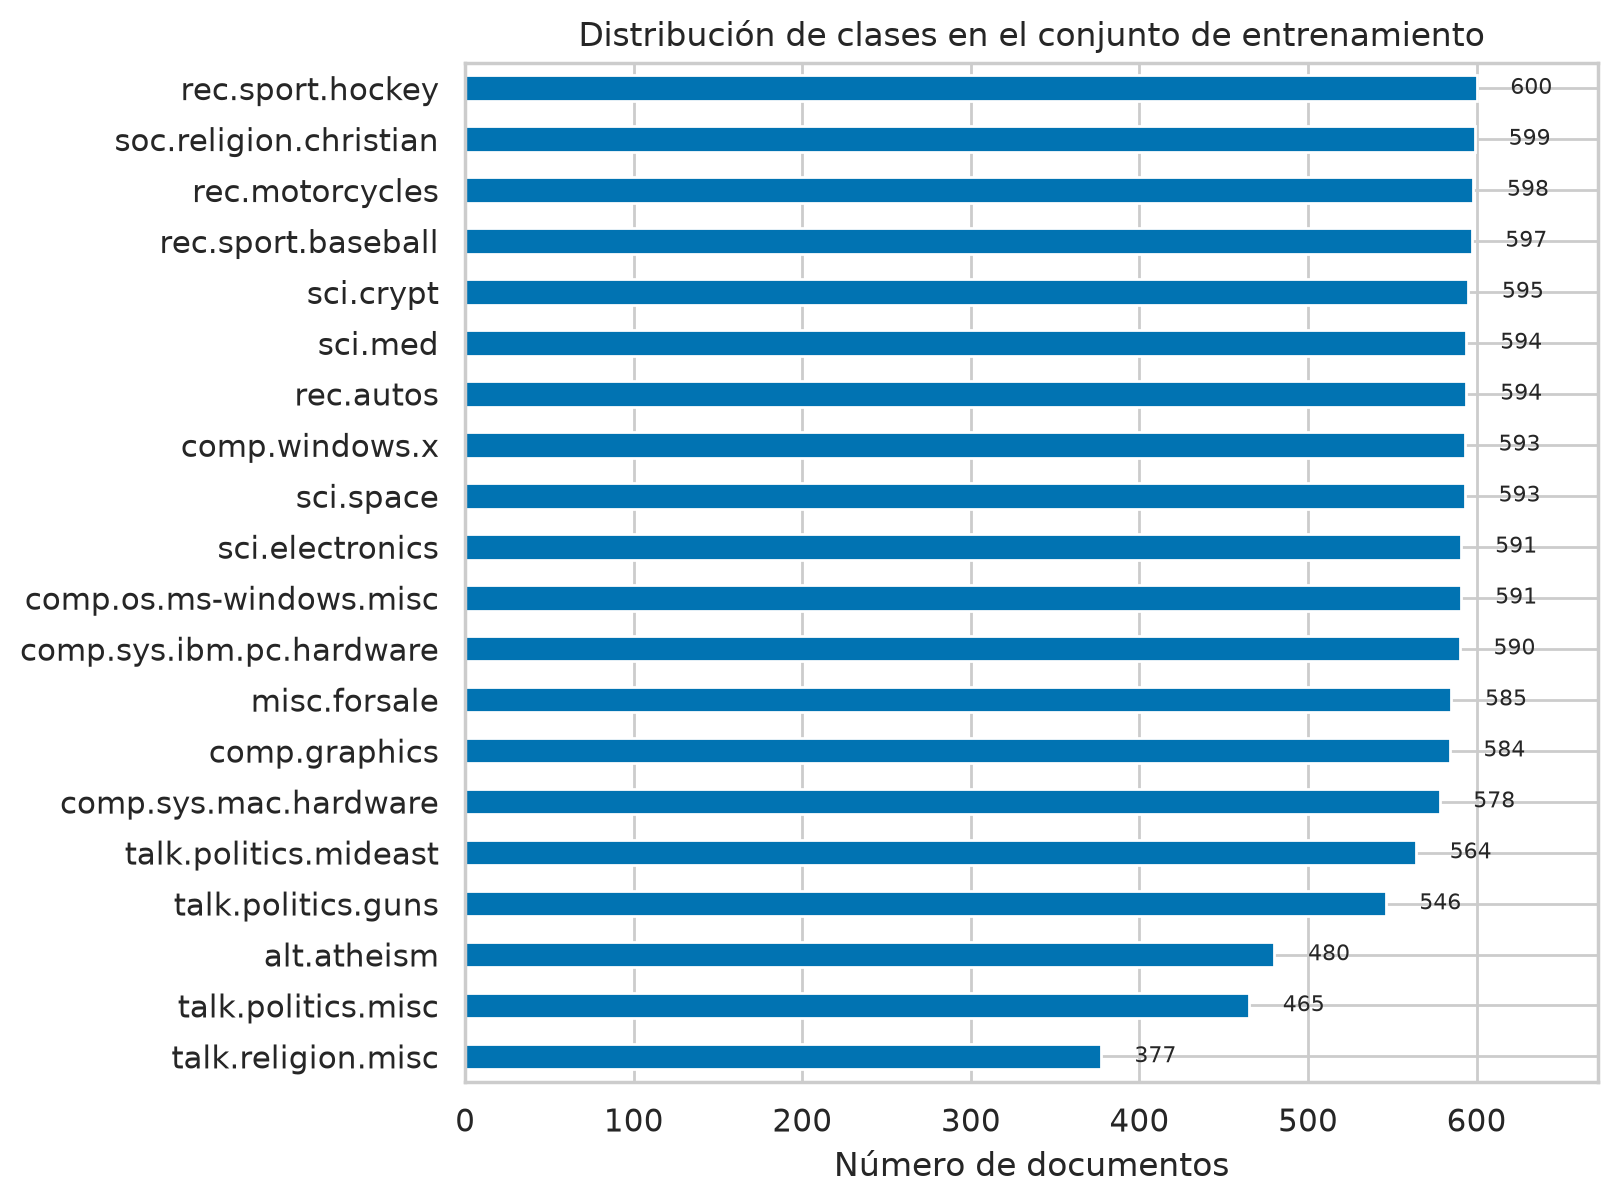

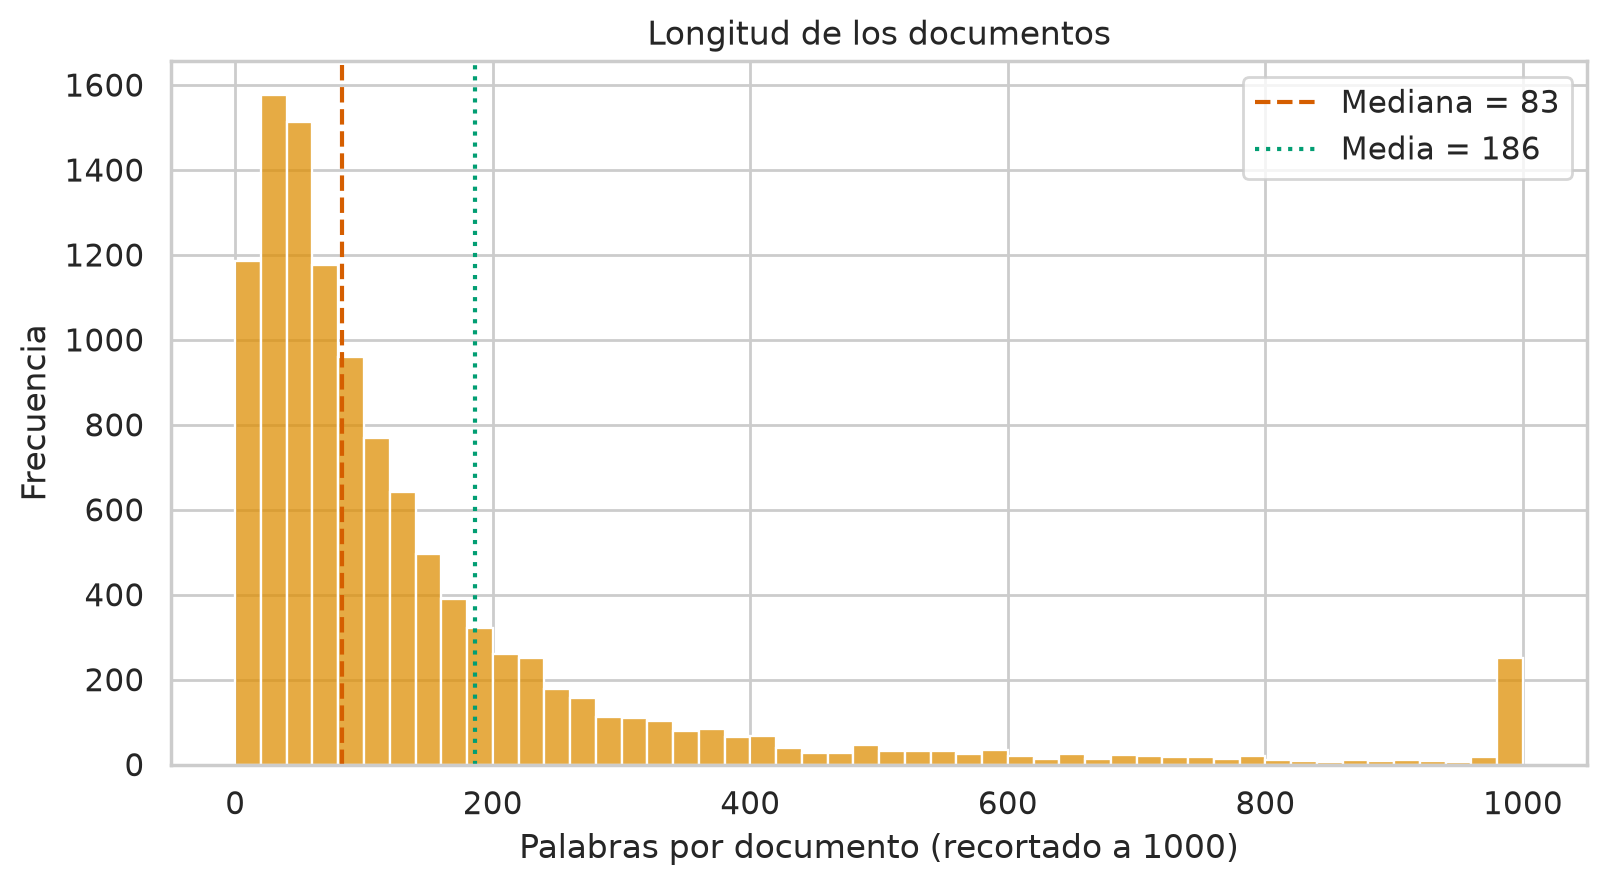

In [3]:
class_counts = train["label_name"].value_counts().rename("Documentos")
display(class_counts.to_frame().T)

display(Image(filename=str(RESULTS_DIR / "figures" / "eda_distribucion_clases.png")))
display(Image(filename=str(RESULTS_DIR / "figures" / "eda_longitud_documentos.png")))

## 2. Preprocesamiento y arquitectura

La entrada del modelo son **textos crudos**. La primera capa,
`TextVectorization`, aplica minúsculas, elimina puntuación y construye un
vocabulario de 20.000 tokens. Luego calcula la representación **TF-IDF** de
cada documento (frecuencia del término ponderada por la frecuencia inversa en
el documento, normalizada). El vectorizador se adapta **solo con el conjunto
de entrenamiento** para no filtrar información del test.

Sobre esa representación se apila una capa densa con activación ReLU, dropout
y una capa de salida softmax:

`TF-IDF (20.000) → Dense 256 + ReLU → Dropout 0.3 → Dense 20 + Softmax`

El barrido de hiperparámetros mostró que una sola capa oculta generaliza mejor
que arquitecturas más profundas para este corpus.

In [4]:
model = load_trained_model()
model.summary()

Model: "mlp_1x256"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ texto (InputLayer)              │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tfidf (TextVectorization)       │ (None, 1, 20000)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_1_256 (Dense)             │ (None, 1, 256)         │     5,120,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1, 20)          │         5,140 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,125,396 (19.55 MB)

 Trainable params: 5,125,396 (19.55 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Condiciones de entrenamiento

| Elemento | Valor |
|---|---|
| Partición | 90 % entrenamiento / 10 % validación (estratificada) |
| Prueba | 7.532 documentos, nunca usados en entrenamiento |
| Optimizador | Adam, tasa de aprendizaje 1e-3 |
| Pérdida | Entropía cruzada categórica dispersa |
| Batch | 128 |
| Épocas máximas | 20 con parada temprana (paciencia 3 sobre `val_loss`) |
| Regularización | Dropout 0.3 |
| Semilla | 42 (determinismo activado) |

,accuracy,loss,top3_accuracy,val_accuracy,val_loss,val_top3_accuracy
5,0.962286,0.209532,0.975643,0.725265,2.393015,0.862191
6,0.965920,0.220692,0.976822,0.717314,2.713562,0.867491
7,0.967393,0.176472,0.977608,0.721731,2.125081,0.865724


Épocas ejecutadas: 8 | mejor época: 3 | parámetros: 5,125,396 | tiempo: 27.9 s


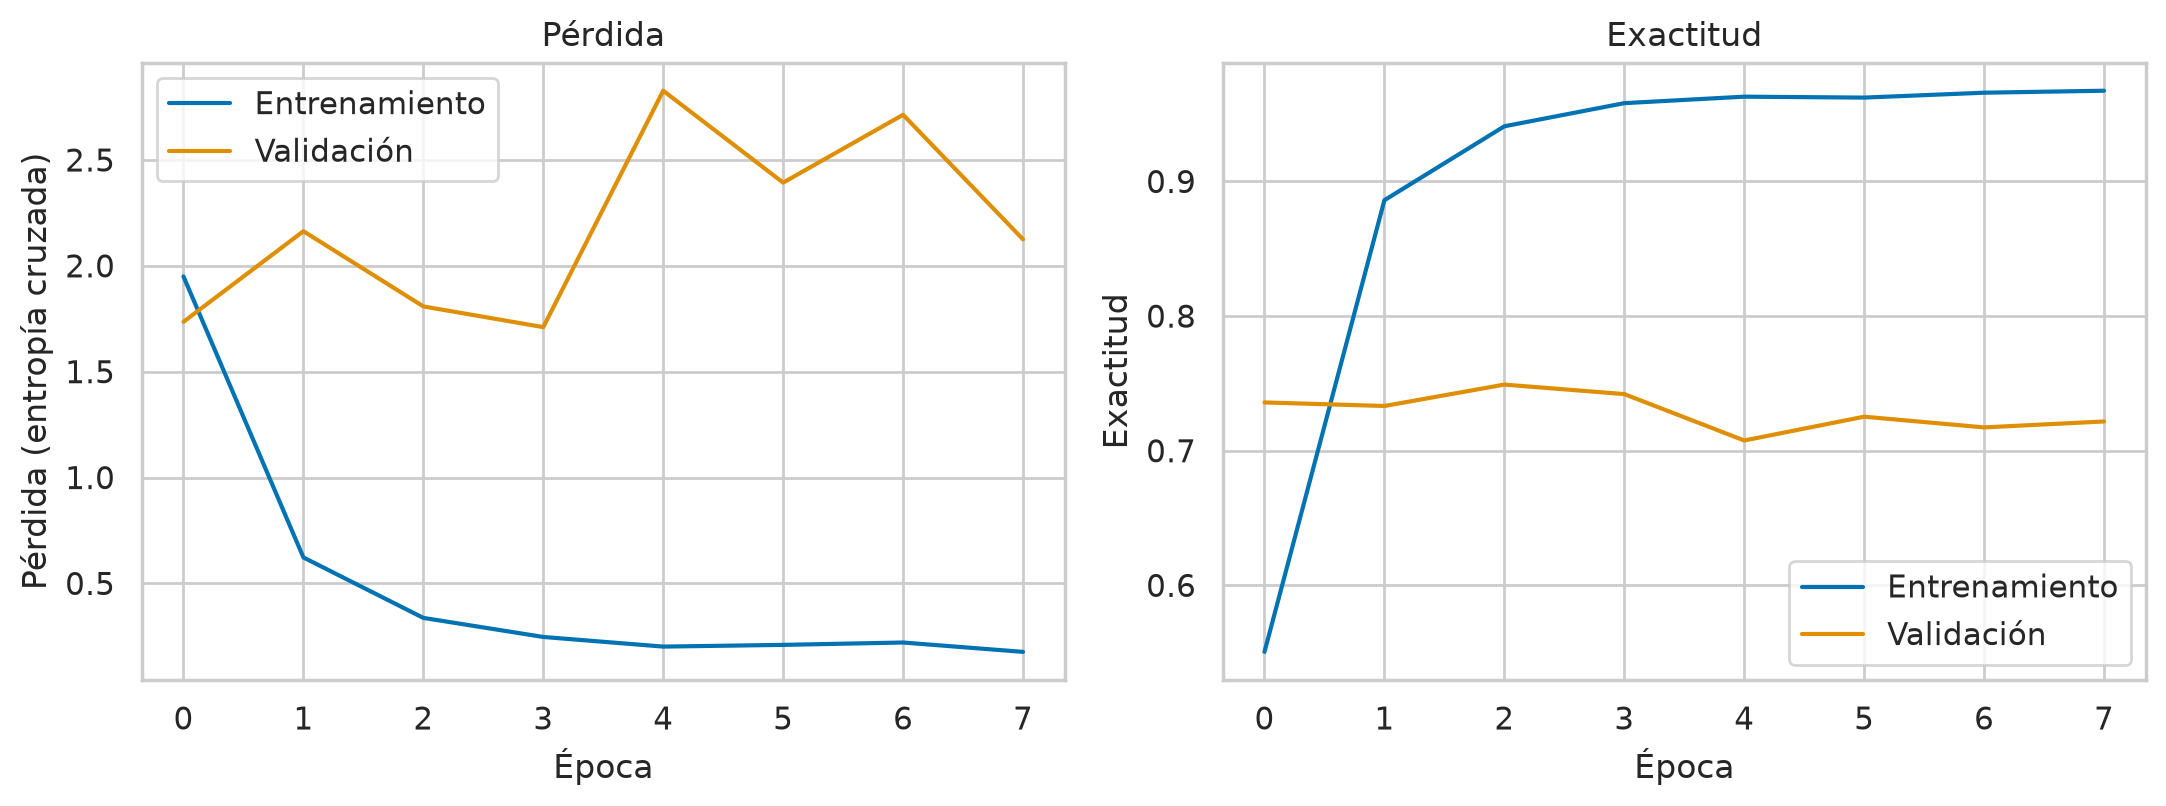

In [5]:
primary_dir = RESULTS_DIR / "runs" / PRIMARY_CONFIG.name
history = pd.read_csv(primary_dir / "history.csv")
result = json.loads((primary_dir / "result.json").read_text())
metrics = json.loads((primary_dir / "metrics.json").read_text())

display(history.tail(3))
print(f"Épocas ejecutadas: {result['epochs_run']} | mejor época: {result['best_epoch']} "
      f"| parámetros: {result['n_parameters']:,} | tiempo: {result['train_time_seconds']:.1f} s")

display(Image(filename=str(RESULTS_DIR / "figures" / "curvas_entrenamiento_primary.png")))

## 4. Evaluación en el conjunto de prueba

Se reportan exactitud, precisión, recall y F1 macro (promedio no ponderado por
clase), F1 ponderado y exactitud top-3. El **F1 macro** es la métrica principal
porque trata todas las clases por igual, independientemente de su frecuencia.

In [6]:
metric_table = pd.DataFrame(
    {
        "Métrica": ["Exactitud", "Precisión macro", "Recall macro", "F1 macro",
                    "F1 ponderado", "Exactitud top-3"],
        "Valor": [metrics["accuracy"], metrics["macro_precision"], metrics["macro_recall"],
                  metrics["macro_f1"], metrics["weighted_f1"], metrics["top3_accuracy"]],
    }
)
metric_table["Valor"] = metric_table["Valor"].map(lambda v: f"{v:.4f}")
display(metric_table)

print(metrics["report_text"])

,Métrica,Valor
0,Exactitud,0.6771
1,Precisión macro,0.6786
2,Recall macro,0.6655
3,F1 macro,0.6663
4,F1 ponderado,0.6762
5,Exactitud top-3,0.8452


                          precision    recall  f1-score   support

             alt.atheism     0.5238    0.4828    0.5024       319
           comp.graphics     0.7302    0.6401    0.6822       389
 comp.os.ms-windows.misc     0.5058    0.6599    0.5727       394
comp.sys.ibm.pc.hardware     0.5942    0.6760    0.6325       392
   comp.sys.mac.hardware     0.7401    0.6805    0.7091       385
          comp.windows.x     0.9036    0.6405    0.7496       395
            misc.forsale     0.7865    0.7744    0.7804       390
               rec.autos     0.7367    0.6641    0.6985       396
         rec.motorcycles     0.7105    0.7462    0.7279       398
      rec.sport.baseball     0.5628    0.8690    0.6832       397
        rec.sport.hockey     0.8906    0.8571    0.8736       399
               sci.crypt     0.7910    0.7071    0.7467       396
         sci.electronics     0.6150    0.5852    0.5997       393
                 sci.med     0.7612    0.7323    0.7465       396
         

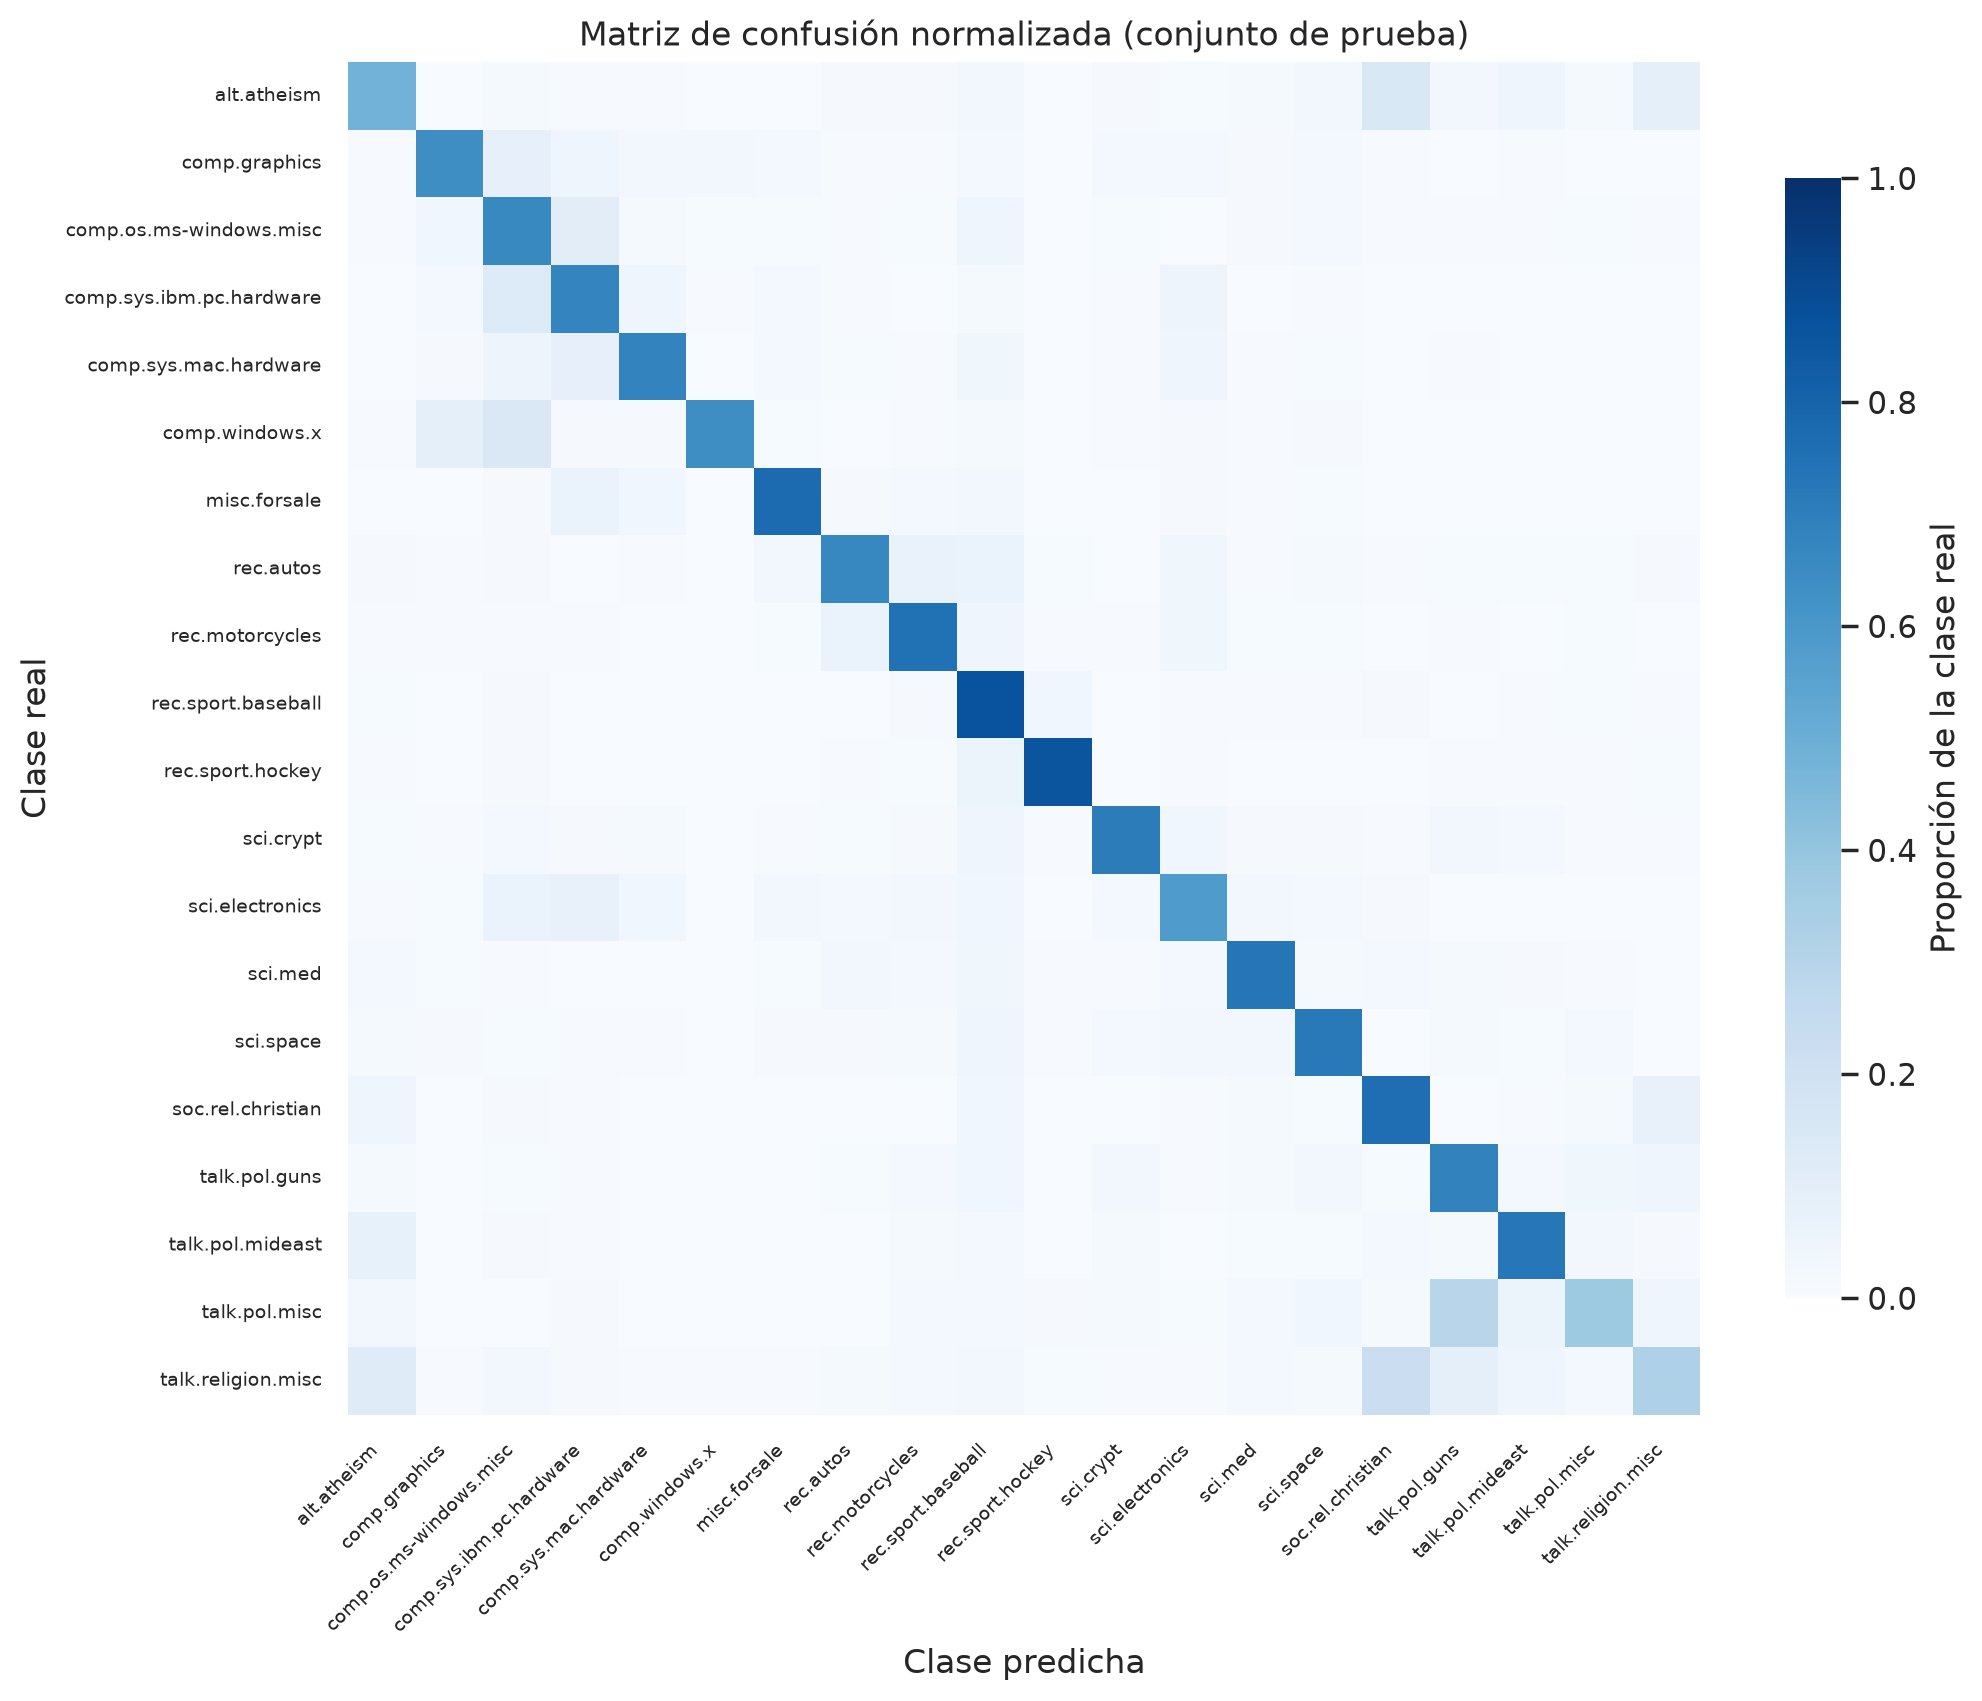

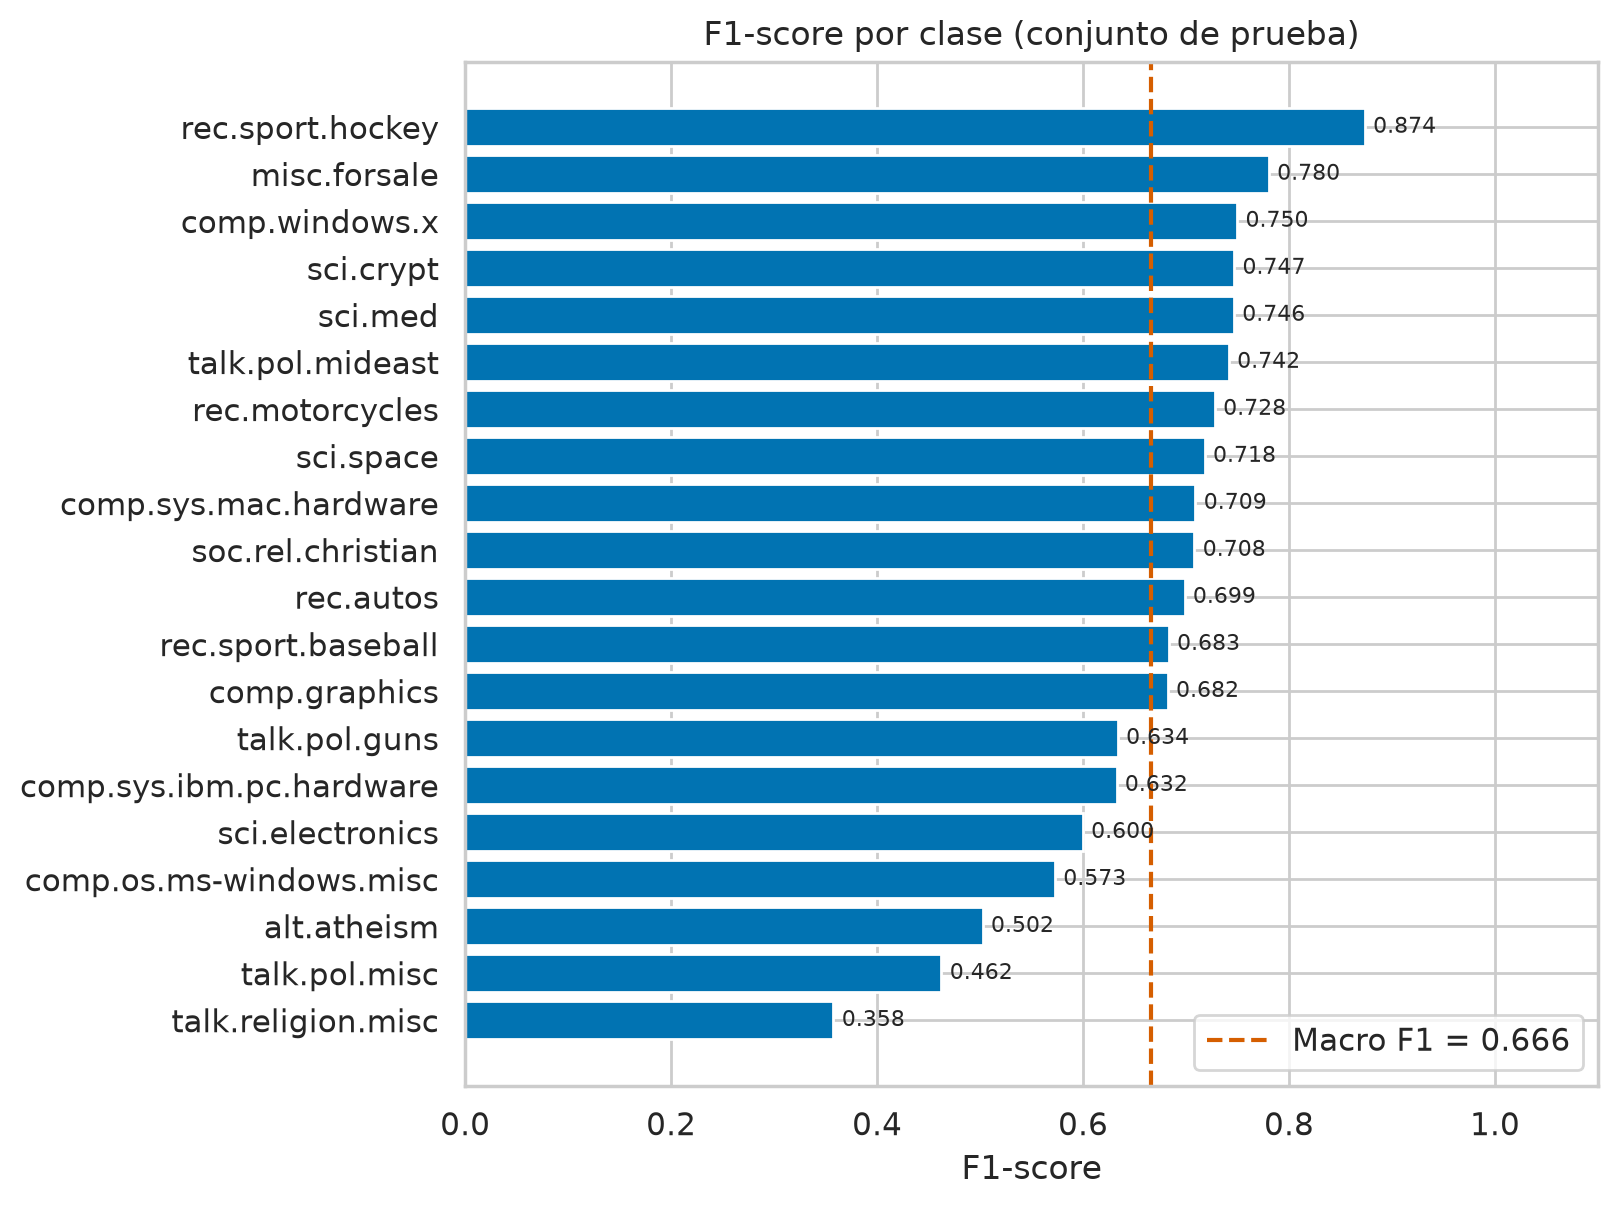

In [7]:
display(Image(filename=str(RESULTS_DIR / "figures" / "matriz_confusion_primary.png")))
display(Image(filename=str(RESULTS_DIR / "figures" / "f1_por_clase_primary.png")))

### Análisis de errores

Las confusiones más frecuentes se concentran entre grupos temáticamente
cercanos: los cinco grupos de computación (`comp.*`), las categorías de
religión (`alt.atheism`, `soc.religion.christian`, `talk.religion.misc`) y los
debates políticos (`talk.politics.*`). Esto es esperable porque comparten
vocabulario y muchos mensajes responden a hilos de otros grupos.

In [8]:
confusions = pd.read_json(RESULTS_DIR / "figures" / "confusiones_principales.json")
display(confusions)

,real,predicha,casos,proporcion_clase_real
0,talk.politics.misc,talk.politics.guns,91,0.293548
1,comp.windows.x,comp.os.ms-windows.misc,58,0.146835
2,talk.religion.misc,soc.religion.christian,56,0.223108
3,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,52,0.132653
4,alt.atheism,soc.religion.christian,48,0.150470
5,comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware,42,0.106599
6,comp.windows.x,comp.graphics,36,0.091139
7,comp.graphics,comp.os.ms-windows.misc,33,0.084833


## 5. Comparación de configuraciones

Se entrenaron siete configuraciones con el mismo protocolo, variando
profundidad, dropout, tamaño de vocabulario y balanceo de clases. La tabla y la
figura se generan en `src/experiments.py`.

,name,hidden_units,dropout_rates,vocab_size,balanced_class_weight,accuracy,macro_f1,top3_accuracy
1,mlp_1x256,256,0.3,20000,False,0.6771,0.6663,0.8452
7,mlp_2x512_256_lr5e4,512-256,0.4-0.3,20000,False,0.6741,0.6653,0.8376
2,mlp_2x512_256,512-256,0.4-0.3,20000,False,0.6680,0.6578,0.8240
6,mlp_2x512_256_balanceado,512-256,0.4-0.3,20000,True,0.6686,0.6568,0.8258
3,mlp_2x512_256_dropout050,512-256,0.5-0.4,20000,False,0.6644,0.6566,0.8266
0,lineal_softmax,sin capas ocultas,-,20000,False,0.6572,0.6451,0.8368
4,mlp_3x512_256_128,512-256-128,0.4-0.3-0.2,20000,False,0.6498,0.6433,0.8140
8,mlp_2x512_256_l2,512-256,0.4-0.3,20000,False,0.6455,0.6393,0.8177
5,mlp_2x512_256_vocab10k,512-256,0.4-0.3,10000,False,0.6439,0.6358,0.8123


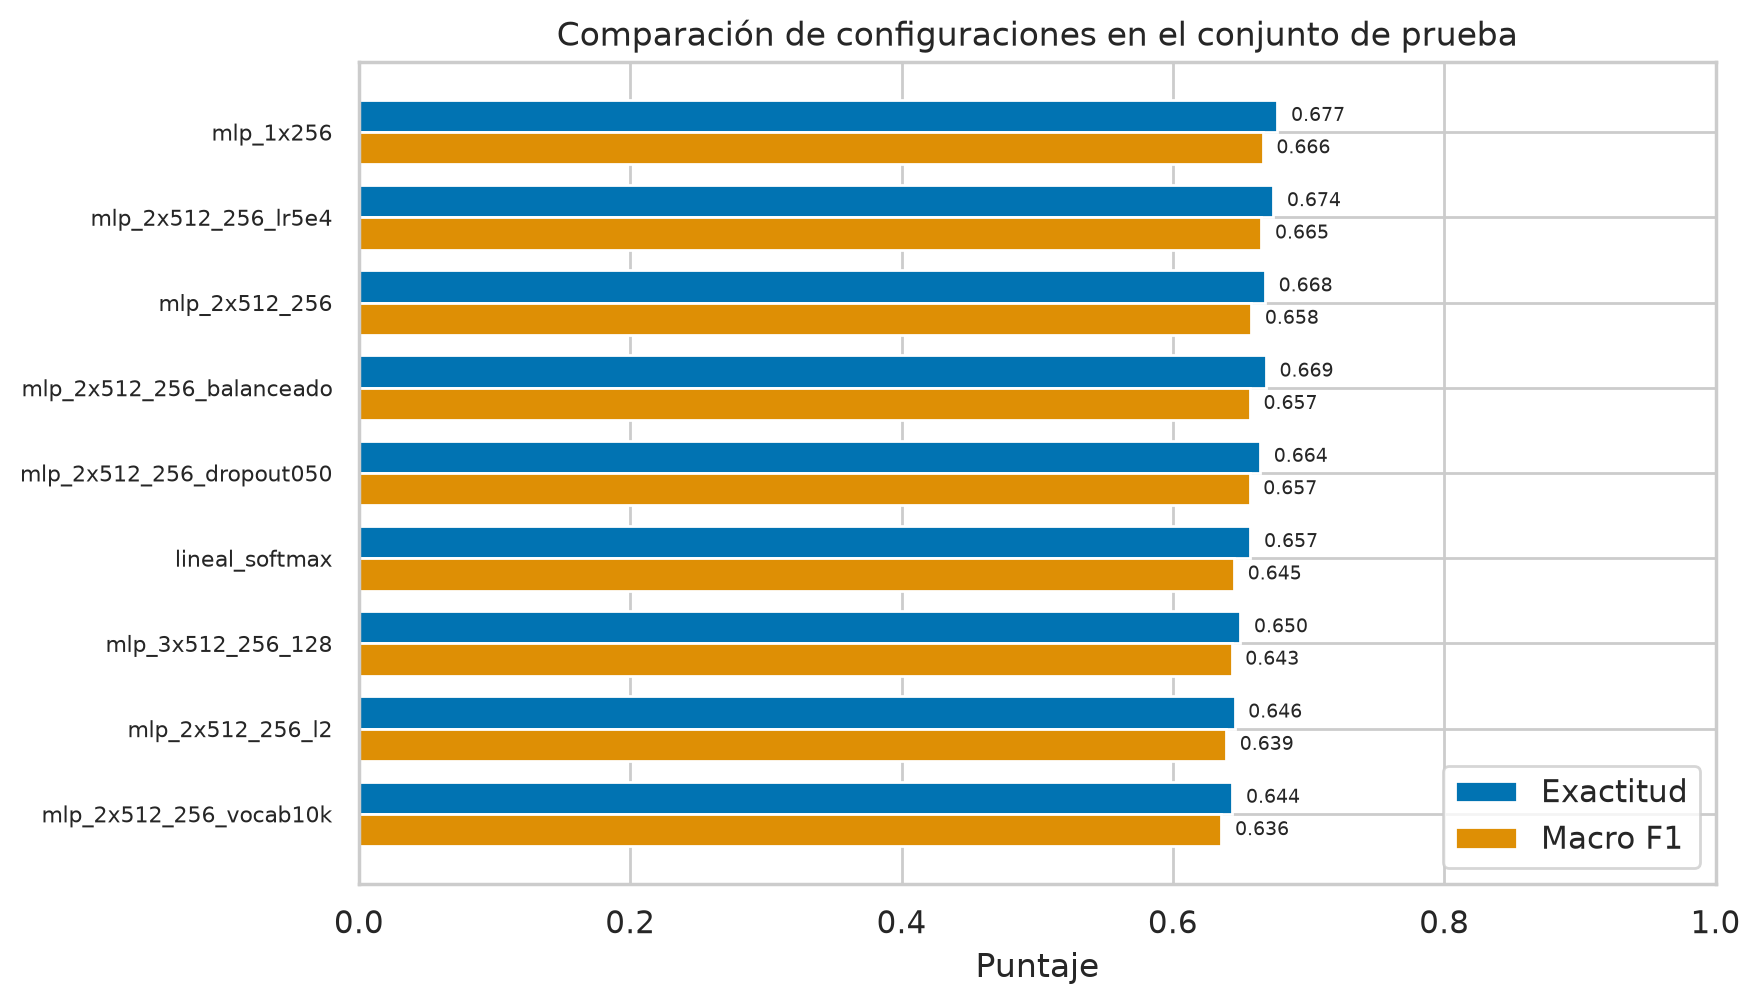

In [9]:
experiments = pd.read_csv(RESULTS_DIR / "experimentos.csv")
display(experiments[["name", "hidden_units", "dropout_rates", "vocab_size",
                     "balanced_class_weight", "accuracy", "macro_f1", "top3_accuracy"]]
        .sort_values("macro_f1", ascending=False)
        .style.format({"accuracy": "{:.4f}", "macro_f1": "{:.4f}", "top3_accuracy": "{:.4f}"}))

display(Image(filename=str(RESULTS_DIR / "figures" / "comparacion_experimentos.png")))

## 6. Demostración

Se clasifican tres textos nuevos (no pertenecientes al corpus) y se muestran
las tres clases más probables.

In [10]:
ejemplos = [
    "My new graphics card works fine, but the X server crashes when I start it. "
    "Which driver version should I use with this kernel?",
    "The team won the hockey game in overtime thanks to a goal by the rookie.",
    "NASA is planning a new mission to study the atmosphere of Mars and its moons.",
]
for item in predict_texts(model, ejemplos, label_names):
    print("\nTexto:", item["texto"])
    print("Predicción:", item["prediccion"], f"({item['confianza']:.2%})")
    for top in item["top_k"]:
        print(f"   {top['clase']:<28s} {top['probabilidad']:.2%}")


Texto: My new graphics card works fine, but the X server crashes when I start it. Which driver version should I use with this kernel?
Predicción: comp.windows.x (40.91%)
   comp.windows.x               40.91%
   comp.graphics                19.70%
   comp.os.ms-windows.misc      14.24%

Texto: The team won the hockey game in overtime thanks to a goal by the rookie.
Predicción: rec.sport.hockey (98.20%)
   rec.sport.hockey             98.20%
   rec.sport.baseball           0.48%
   comp.sys.mac.hardware        0.13%

Texto: NASA is planning a new mission to study the atmosphere of Mars and its moons.
Predicción: sci.space (86.18%)
   sci.space                    86.18%
   comp.os.ms-windows.misc      1.70%
   sci.med                      1.25%


## 7. Reproducibilidad

```bash
# Crear entorno e instalar dependencias
uv venv --python 3.12 .venv
uv pip install --python .venv/bin/python -r requirements.txt

# Descargar datos, entrenar las 7 configuraciones y generar figuras
.venv/bin/python -m src.experiments

# Predicción por línea de comandos
.venv/bin/python -m src.predict "texto a clasificar"
```

Para reentrenar el modelo principal desde este notebook, cambie `ENTRENAR` a
`True` en la siguiente celda (tarda unos minutos en CPU).

In [11]:
ENTRENAR = False
if ENTRENAR:
    from src.train import run_experiment
    run_experiment(PRIMARY_CONFIG)

## 8. Conclusiones

- La MLP con representación TF-IDF alcanza una exactitud cercana al 68 % y un
  F1 macro cercano a 0.67 en 20 clases, muy por encima del azar (5 %).
- La representación TF-IDF permite que una red puramente densa supere a los
  modelos lineales clásicos: el modelo lineal ya es un baseline fuerte
  (~66 %), y una capa oculta aporta una mejora consistente.
- El dropout y la parada temprana controlan el sobreajuste: la exactitud de
  entrenamiento supera el 95 % mientras la de validación se estabiliza
  alrededor del 75 %.
- Los errores se concentran en clases semánticamente solapadas, lo que sugiere
  que la siguiente etapa (RNN/Transformer) debe capturar mejor el contexto y
  el orden de las palabras.